In [3]:
import os, re, json, time, shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_recall_fscore_support,
)

SEED = 42
tf.keras.utils.set_random_seed(SEED)

DATASET_DIR = (
    "/kaggle/input/datasets/goyam07/food-classification/"
    "AgriFreshNET Freshness and Shelf-Life Image Datase/Processed Data/Processed Data"
)
OUT_DIR = "/kaggle/working"
CUSTOM_SIZE, MOBILE_SIZE = 128, 224
BATCH_SIZE = 32
CUSTOM_EPOCHS, MOBILE_EPOCHS = 60, 30
MOBILE_WEIGHTS = "imagenet"
# ------------------------------------------

MODEL_DIR = f"{OUT_DIR}/models"
FIG_DIR = f"{OUT_DIR}/figures"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

CUSTOM_PATH = f"{MODEL_DIR}/best_custom_cnn_fixed.keras"   
MOBILE_PATH = f"{MODEL_DIR}/best_mobilenetv2.keras"      

CLASS_NAMES = ["Fresh", "Semi-Fresh", "Rotten"]
AUTOTUNE = tf.data.AUTOTUNE
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
rows = []
for folder in sorted(os.listdir(DATASET_DIR)):
    fpath = os.path.join(DATASET_DIR, folder)
    if not os.path.isdir(fpath):
        continue
    low = folder.lower()
    if low.startswith("semi"):
        freshness = "Semi-Fresh"
    elif low.startswith("rotten"):
        freshness = "Rotten"
    elif low.startswith("fresh"):
        freshness = "Fresh"
    else:
        continue

    produce = re.sub(r"\(.*?\)", "", folder).strip()
    produce = re.sub(r"^(semi[\s_]*fresh|semi|fresh|rotten)[\s_]*", "", produce, flags=re.I).strip().lower()
    for fn in os.listdir(fpath):
        if fn.lower().endswith(IMAGE_EXTS):
            rows.append({
                "image_path": os.path.join(fpath, fn),
                "produce": produce,
                "freshness": freshness,
                "label": CLASS_NAMES.index(freshness),
            })

df = pd.DataFrame(rows)
print("Total images:", len(df))
print(df["freshness"].value_counts())
print("Produce types:", sorted(df["produce"].unique()))


train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"])
print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}")

Total images: 14160
freshness
Fresh         4720
Rotten        4720
Semi-Fresh    4720
Name: count, dtype: int64
Produce types: ['banana', 'bittermelon', 'cucumber', 'eggplant', 'orange', 'papaya', 'pineapple', 'tomato']
Train 9912 | Val 2124 | Test 2124


In [5]:


def make_loader(size):
    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.io.decode_image(img, channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        img = tf.image.resize(img, [size, size])
        return tf.cast(tf.round(img), tf.uint8), label
    return load


augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomBrightness(0.10, value_range=(-1, 1)),
    layers.RandomContrast(0.10, value_range=(-1, 1)),
], name="augmentation")

def to_model_range(x, y):
  
    return tf.cast(x, tf.float32) / 127.5 - 1.0, y

def build_ds(dataframe, size, training):
    ds = tf.data.Dataset.from_tensor_slices(
        (dataframe["image_path"].values, dataframe["label"].values.astype("int32"))
    )
    ds = ds.map(make_loader(size), num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(to_model_range, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

c_train, c_val, c_test = (build_ds(d, CUSTOM_SIZE, t) for d, t in [(train_df, True), (val_df, False), (test_df, False)])
m_train, m_val, m_test = (build_ds(d, MOBILE_SIZE, t) for d, t in [(train_df, True), (val_df, False), (test_df, False)])
print("Datasets ready")

Datasets ready


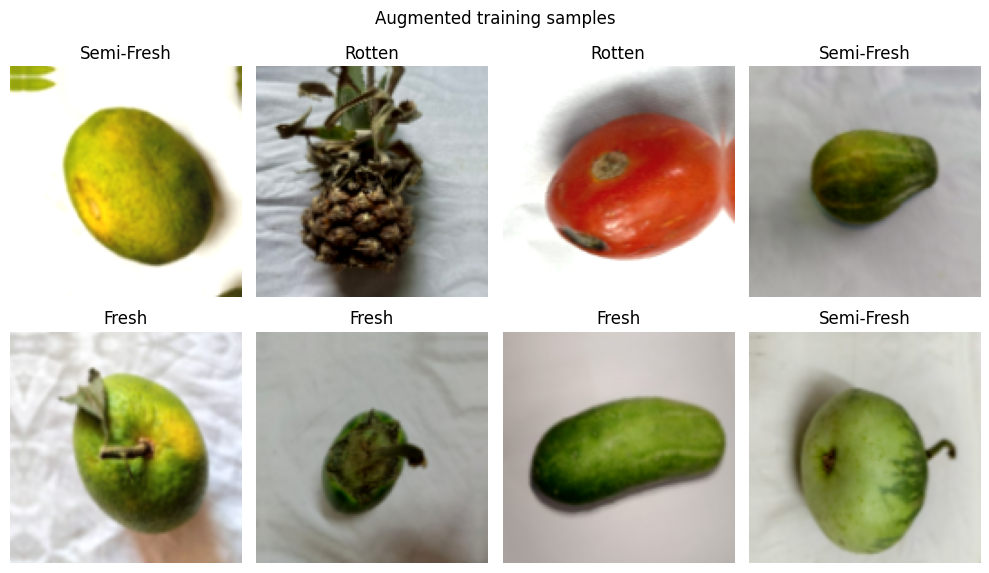

In [6]:

for imgs, labs in c_train.take(1):
    plt.figure(figsize=(10, 6))
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow((imgs[i].numpy() + 1) / 2)
        plt.title(CLASS_NAMES[int(labs[i])])
        plt.axis("off")
    plt.suptitle("Augmented training samples")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/augmented_samples.png", dpi=150)
    plt.show()

In [7]:

def conv_block(x, filters, spatial_drop=0.0):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)
    if spatial_drop:
        x = layers.SpatialDropout2D(spatial_drop)(x)
    return x

def build_custom_cnn():
    inputs = layers.Input((CUSTOM_SIZE, CUSTOM_SIZE, 3))
    x = conv_block(inputs, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128, 0.10)
    x = conv_block(x, 256, 0.10)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(3, activation="softmax")(x)
    return models.Model(inputs, outputs, name="custom_cnn")

def callbacks_for(path, patience):
    return [
        tf.keras.callbacks.ModelCheckpoint(path, monitor="val_loss", save_best_only=True, mode="min", verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    ]

custom_model = build_custom_cnn()
custom_model.summary()
custom_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             

 Total params: 1,241,699 (4.74 MB)

 Trainable params: 1,239,779 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [8]:
custom_history = custom_model.fit(
    c_train, validation_data=c_val,
    epochs=CUSTOM_EPOCHS, callbacks=callbacks_for(CUSTOM_PATH, patience=10),
)

Epoch 1/60


E0000 00:00:1795350929.027699     150 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795350930.593190     150 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795350931.550315     150 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


309/310 ━━━━━━━━━━━━━━━━━━━━ 0s 759ms/step - accuracy: 0.4744 - loss: 1.0689

E0000 00:00:1795351177.387824     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795351178.617972     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795351179.372105     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 801ms/step - accuracy: 0.4745 - loss: 1.0687
Epoch 1: val_loss improved from None to 1.03291, saving model to /kaggle/working/models/best_custom_cnn_fixed.keras

Epoch 1: finished saving model to /kaggle/working/models/best_custom_cnn_fixed.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 332s 1s/step - accuracy: 0.4997 - loss: 1.0034 - val_accuracy: 0.4218 - val_loss: 1.0329 - learning_rate: 0.0010
Epoch 2/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5261 - loss: 0.9396
Epoch 2: val_loss improved from 1.03291 to 1.00957, saving model to /kaggle/working/models/best_custom_cnn_fixed.keras

Epoch 2: finished saving model to /kaggle/working/models/best_custom_cnn_fixed.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 25s 79ms/step - accuracy: 0.5327 - loss: 0.9354 - val_accuracy: 0.4958 - val_loss: 1.0096 - learning_rate: 0.0010
Epoch 3/60
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.5303 - loss: 0.9186
Epoch 3: val_loss improved from 1.00957 to 0.87090, savin

In [9]:

base = tf.keras.applications.MobileNetV2(
    weights=MOBILE_WEIGHTS, include_top=False, input_shape=(MOBILE_SIZE, MOBILE_SIZE, 3)
)
base.trainable = False

inputs = layers.Input((MOBILE_SIZE, MOBILE_SIZE, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(3, activation="softmax")(x)
mobile_model = models.Model(inputs, outputs, name="mobilenetv2_feature_extractor")
mobile_model.summary()

mobile_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_feature_extractor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,586,691 (9.87 MB)

 Trainable params: 328,707 (1.25 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
mobile_history = mobile_model.fit(
    m_train, validation_data=m_val,
    epochs=MOBILE_EPOCHS, callbacks=callbacks_for(MOBILE_PATH, patience=6),
)

Epoch 1/30
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.6337 - loss: 0.7938
Epoch 1: val_loss improved from None to 0.50301, saving model to /kaggle/working/models/best_mobilenetv2.keras

Epoch 1: finished saving model to /kaggle/working/models/best_mobilenetv2.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 98s 269ms/step - accuracy: 0.7080 - loss: 0.6474 - val_accuracy: 0.7707 - val_loss: 0.5030 - learning_rate: 0.0010
Epoch 2/30
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.7953 - loss: 0.4734
Epoch 2: val_loss improved from 0.50301 to 0.39544, saving model to /kaggle/working/models/best_mobilenetv2.keras

Epoch 2: finished saving model to /kaggle/working/models/best_mobilenetv2.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 65s 208ms/step - accuracy: 0.8064 - loss: 0.4556 - val_accuracy: 0.8470 - val_loss: 0.3954 - learning_rate: 0.0010
Epoch 3/30
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.8364 - loss: 0.4047
Epoch 3: val_loss improved from 0.39544 to 0.35413, saving mo

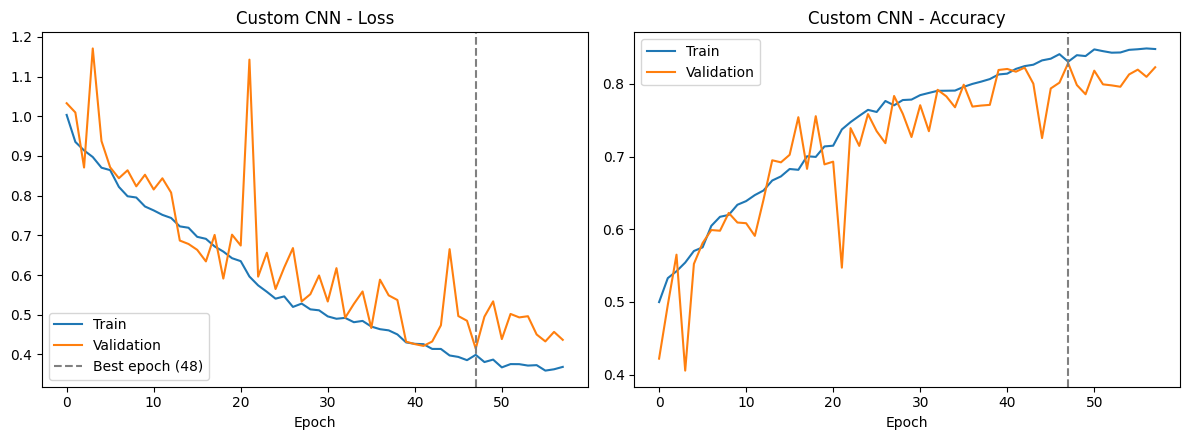

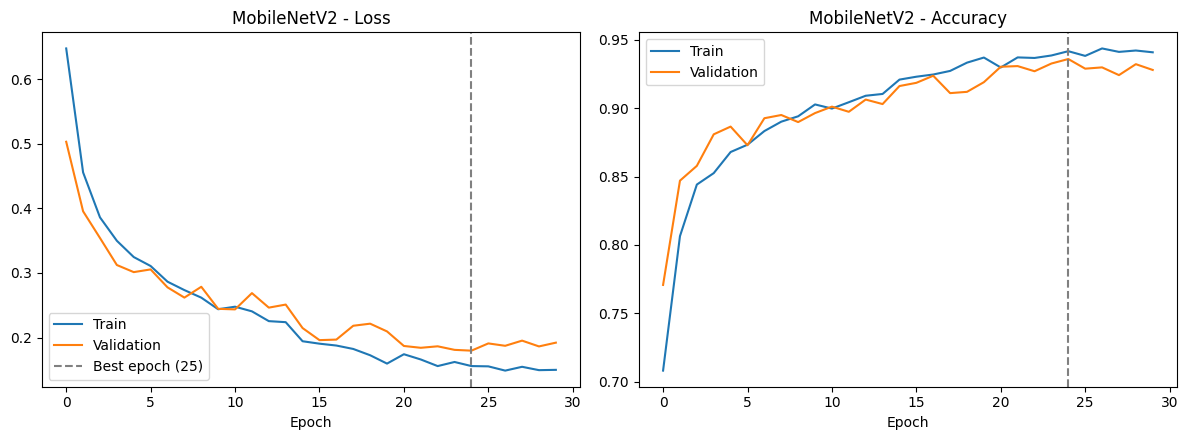

In [11]:

def plot_history(history, title, fname):
    h = history.history
    best = int(np.argmin(h["val_loss"]))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].plot(h["loss"], label="Train"); ax[0].plot(h["val_loss"], label="Validation")
    ax[0].axvline(best, color="grey", ls="--", label=f"Best epoch ({best + 1})")
    ax[0].set_title(f"{title} - Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="Train"); ax[1].plot(h["val_accuracy"], label="Validation")
    ax[1].axvline(best, color="grey", ls="--")
    ax[1].set_title(f"{title} - Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{fname}", dpi=150); plt.show()

plot_history(custom_history, "Custom CNN", "custom_cnn_curves.png")
plot_history(mobile_history, "MobileNetV2", "mobilenetv2_curves.png")


===== Custom CNN =====
              precision    recall  f1-score   support

       Fresh     0.8466    0.8107    0.8283       708
  Semi-Fresh     0.8173    0.7076    0.7585       708
      Rotten     0.8043    0.9463    0.8696       708

    accuracy                         0.8216      2124
   macro avg     0.8227    0.8216    0.8188      2124
weighted avg     0.8227    0.8216    0.8188      2124



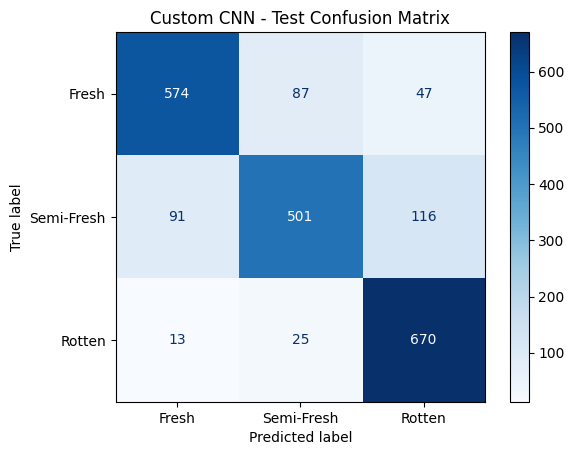


===== MobileNetV2 =====
              precision    recall  f1-score   support

       Fresh     0.9245    0.9336    0.9290       708
  Semi-Fresh     0.9241    0.8941    0.9088       708
      Rotten     0.9558    0.9774    0.9665       708

    accuracy                         0.9350      2124
   macro avg     0.9348    0.9350    0.9348      2124
weighted avg     0.9348    0.9350    0.9348      2124



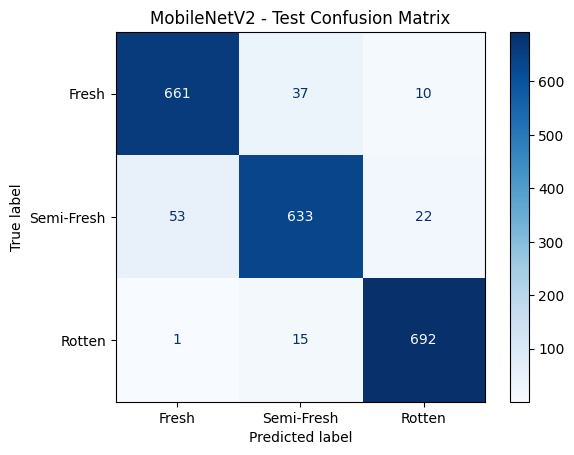

In [12]:

def evaluate_saved(path, test_ds, name):
    model = tf.keras.models.load_model(path, compile=False)   
    t0 = time.time()
    probs = model.predict(test_ds, verbose=0)
    ms_per_image = (time.time() - t0) / len(probs) * 1000
    y_true = test_df["label"].values            
    y_pred = np.argmax(probs, axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)
    per_f1 = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)[2]
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", values_format="d")
    plt.title(f"{name} - Test Confusion Matrix")
    plt.savefig(f"{FIG_DIR}/{name.lower().replace(' ', '_')}_confusion.png", dpi=150, bbox_inches="tight")
    plt.show()
    return {
        "model": model, "y_pred": y_pred, "cm": cm,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": p, "macro_recall": r, "macro_f1": f1,
        "f1_fresh": per_f1[0], "f1_semi": per_f1[1], "f1_rotten": per_f1[2],
        "total_params": int(model.count_params()),
        "trainable_params": int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        "size_mb": os.path.getsize(path) / 1e6,
        "ms_per_image": ms_per_image,
    }

custom_res = evaluate_saved(CUSTOM_PATH, c_test, "Custom CNN")
mobile_res = evaluate_saved(MOBILE_PATH, m_test, "MobileNetV2")

In [13]:

comparison = pd.DataFrame({
    "Metric": ["Test accuracy (%)", "Macro precision", "Macro recall", "Macro F1",
               "F1 - Fresh", "F1 - Semi-Fresh", "F1 - Rotten",
               "Total parameters", "Trainable parameters", "File size (MB)", "Inference (ms/image, batched)"],
    "Custom CNN": [
        custom_res["accuracy"] * 100, custom_res["macro_precision"], custom_res["macro_recall"], custom_res["macro_f1"],
        custom_res["f1_fresh"], custom_res["f1_semi"], custom_res["f1_rotten"],
        custom_res["total_params"], custom_res["trainable_params"], custom_res["size_mb"], custom_res["ms_per_image"]],
    "MobileNetV2": [
        mobile_res["accuracy"] * 100, mobile_res["macro_precision"], mobile_res["macro_recall"], mobile_res["macro_f1"],
        mobile_res["f1_fresh"], mobile_res["f1_semi"], mobile_res["f1_rotten"],
        mobile_res["total_params"], mobile_res["trainable_params"], mobile_res["size_mb"], mobile_res["ms_per_image"]],
})
def fmt(metric, v):
    if "parameters" in metric:
        return f"{int(v):,}"
    return f"{v:.2f}" if ("%" in metric or "MB" in metric or "ms" in metric) else f"{v:.4f}"

for col in ["Custom CNN", "MobileNetV2"]:
    comparison[col] = [fmt(m, v) for m, v in zip(comparison["Metric"], comparison[col])]
print(comparison.to_string(index=False))
comparison.to_csv(f"{FIG_DIR}/comparison.csv", index=False)

                       Metric Custom CNN MobileNetV2
            Test accuracy (%)      82.16       93.50
              Macro precision     0.8227      0.9348
                 Macro recall     0.8216      0.9350
                     Macro F1     0.8188      0.9348
                   F1 - Fresh     0.8283      0.9290
              F1 - Semi-Fresh     0.7585      0.9088
                  F1 - Rotten     0.8696      0.9665
             Total parameters  1,241,699   2,586,691
         Trainable parameters  1,239,779     328,707
               File size (MB)      15.03       13.57
Inference (ms/image, batched)      32.10        4.02


             Custom CNN acc (%)  MobileNetV2 acc (%)
produce                                             
eggplant                  63.64                87.60
tomato                    78.54                89.66
pineapple                 89.88                90.27
banana                    95.07                95.07
orange                    91.35                95.11
cucumber                  76.36                95.35
papaya                    68.26                95.90
bittermelon               93.16                98.10


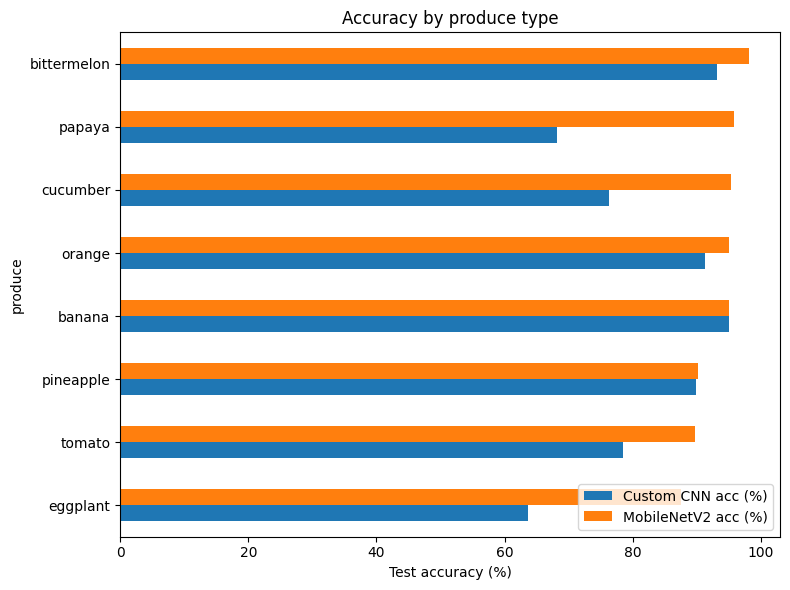

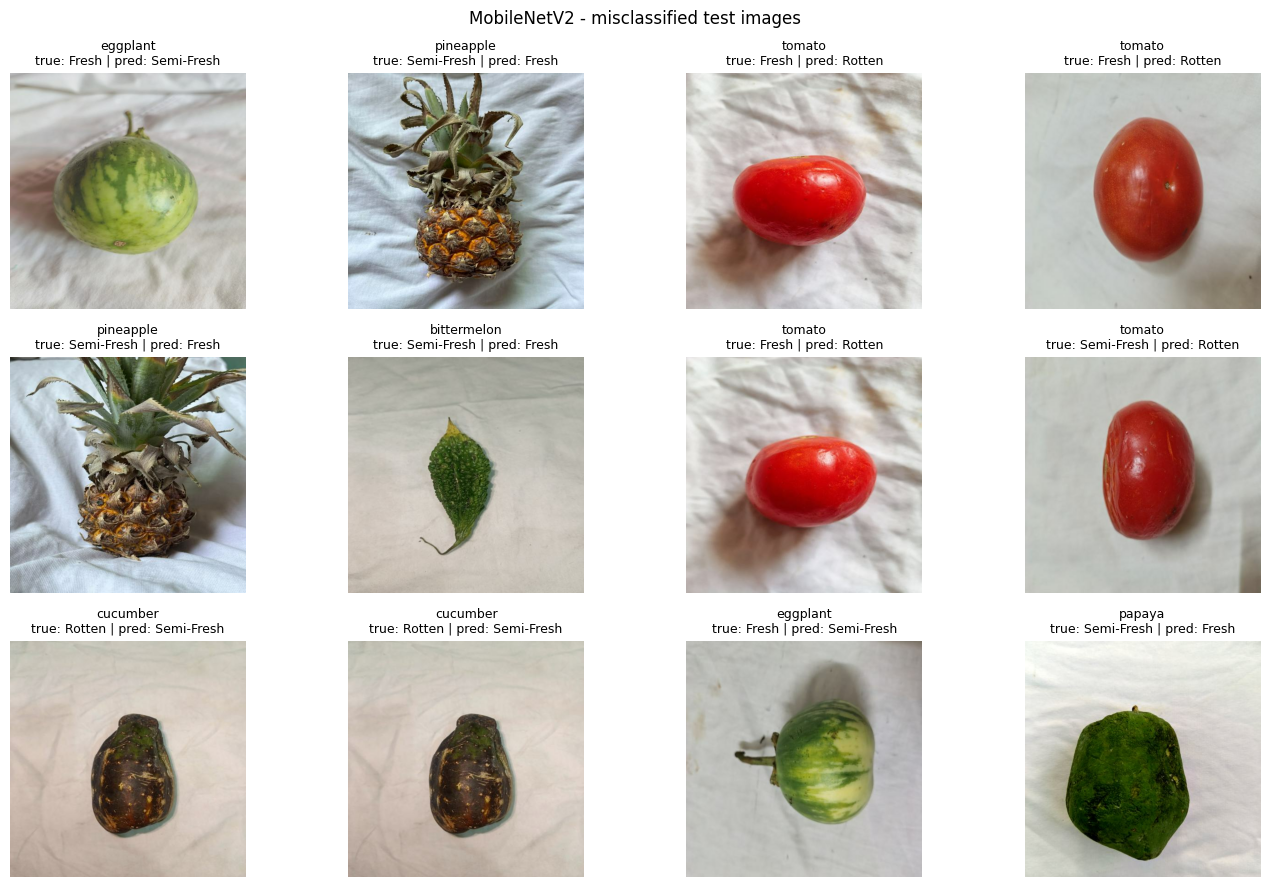

In [14]:

analysis = test_df[["produce", "freshness", "label"]].copy()
analysis["custom_ok"] = custom_res["y_pred"] == analysis["label"].values
analysis["mobile_ok"] = mobile_res["y_pred"] == analysis["label"].values
by_produce = (analysis.groupby("produce")[["custom_ok", "mobile_ok"]].mean() * 100).round(2)
by_produce.columns = ["Custom CNN acc (%)", "MobileNetV2 acc (%)"]
print(by_produce.sort_values("MobileNetV2 acc (%)"))
by_produce.to_csv(f"{FIG_DIR}/accuracy_by_produce.csv")

ax = by_produce.sort_values("MobileNetV2 acc (%)").plot.barh(figsize=(8, 6))
ax.set_xlabel("Test accuracy (%)"); ax.set_title("Accuracy by produce type")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/accuracy_by_produce.png", dpi=150); plt.show()

# misclassified examples (MobileNetV2)
wrong = np.where(mobile_res["y_pred"] != test_df["label"].values)[0]
rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=min(12, len(wrong)), replace=False)
plt.figure(figsize=(14, 9))
for i, idx in enumerate(show):
    row = test_df.iloc[idx]
    img = tf.io.decode_image(tf.io.read_file(row["image_path"]), channels=3, expand_animations=False).numpy()
    plt.subplot(3, 4, i + 1)
    plt.imshow(img); plt.axis("off")
    plt.title(f"{row['produce']}\ntrue: {row['freshness']} | pred: {CLASS_NAMES[mobile_res['y_pred'][idx]]}", fontsize=9)
plt.suptitle("MobileNetV2 - misclassified test images")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/misclassified_examples.png", dpi=150); plt.show()